In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.tools import add_constant
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", InterpolationWarning)     # KPSS: p-values outside its table are printed as bounds

from common import make_features, evaluate, fit_eval, forecast_frame, summarize, save_result, load_results
from common import save_model, load_model

# SARIMAX: Hourly Electricity Consumption

**Contents**

1. Data: feature engineering, train / validation / test split (time index `date_from_utc`)
2. Time series analysis of the target: daily, weekly and yearly seasonality
3. Features: the X of the daily model mapped to the hourly columns, correlation and VIF, the final X
4. Model: regression with ARMA errors in levels (the form of the daily Model 2), estimated in two steps
   - Why this form, stationarity of the regression residuals, order selection, residual analysis, conclusion
5. Final model evaluation
   - Validation: forecast horizons h = 1 to 24 hours
   - Test: forecasts on 2024
   - Saved model
6. Forecast files
7. Conclusion

**Data split:** fit 2019–2022, validation 2023, test 2024 (the final model is fitted once more on 2019–2023 for the test).

**Estimation:** the X coefficients by OLS, then the ARMA parameters by maximum likelihood (see Model); every fit is saved to its own JSON right after it finishes.

# Data
### Feature Engineering
Two features are made in the notebook (`make_features` in common.py, the same as for the daily data):
- `is_holiday_weekday`: `is_holiday` × `is_weekday`. A holiday on a weekday lowers the load much more than a holiday on a weekend.
- `solar_generation_proxy`: `solar_capacity_mw` × `shortwave_radiation` (the hourly radiation).

In [2]:
data_hourly = pd.read_csv(
    "../../data/final/data_hourly.csv",
    parse_dates = ['date_from', 'date_from_utc'])

# UTC as index: unique and regular (the local 02:00 is missing / there twice on the DST days)
data_hourly.index = pd.to_datetime(data_hourly["date_from_utc"]).values

# interaction term and solar generation proxy, see common.py
data_hourly = make_features(data_hourly)

### Train (and Val), Test split

Use 2024-01-01 as the cutting point:
- 5/6 of the data goes to train/val set
- 1/6 of the data goes to the test set

The split follows the local calendar, as for the daily data and in the shared setup: a year starts at local midnight on 1 January, which is 23:00 UTC of the day before. The time index is `date_from_utc` (continuous, no gaps or doubles at the daylight saving time changes), so the boundaries in UTC are:

| Part | Local dates | `date_from_utc` |
|---|---|---|
| Fit | 2019-01-01 to 2022-12-31 | 2018-12-31 23:00 to 2022-12-31 22:00 |
| Validation | 2023-01-01 to 2023-12-31 | 2022-12-31 23:00 to 2023-12-31 22:00 |
| Test | 2024-01-01 to 2024-12-31 | 2023-12-31 23:00 to 2024-12-31 22:00 |

The 24-hour forecasts start at every local midnight (the first hour of each local date), as in the shared setup.


In [3]:
# validation = local year 2023: from the UTC time of local 2023-01-01 00:00 to that of local 2023-12-31 23:00
VAL_START = data_hourly.loc[data_hourly["date_from"] >= "2023-01-01", "date_from_utc"].min()
VAL_END = data_hourly.loc[data_hourly["date_from"] < "2024-01-01", "date_from_utc"].max()
TEST_START = data_hourly.loc[data_hourly["date_from"] >= "2024-01-01", "date_from_utc"].min()
FIT_END = VAL_START - pd.Timedelta(1, "h")          # last hour of the fit period (local 2022-12-31 23:00)

# * forecast origins of the 24-hour forecasts: every local midnight, as UTC times
origins = pd.DatetimeIndex(data_hourly.loc[data_hourly["date_from"].dt.hour == 0, "date_from_utc"])

y_all = data_hourly["actual_consumption"].asfreq("h")      # 2019-2024
y = y_all[:VAL_END]                                       # fit + validation (the test year is not in it)

print("fit:", y.index.min(), "to", FIT_END, "| validation:", VAL_START, "to", VAL_END, "| test from", TEST_START)
print("origins in 2023:", ((origins >= VAL_START) & (origins <= VAL_END)).sum(), "| in 2024:", (origins >= TEST_START).sum())

fit: 2018-12-31 23:00:00 to 2022-12-31 22:00:00 | validation: 2022-12-31 23:00:00 to 2023-12-31 22:00:00 | test from 2023-12-31 23:00:00
origins in 2023: 365 | in 2024: 366


# Time Series Analysis of the Target

The hourly consumption has three seasonal cycles: the day (24 hours), the week (168 hours) and the year. The figures show the mean daily profile by type of day, the weekly mean load, and the autocorrelation up to two weeks, all on the fit period 2019–2022.

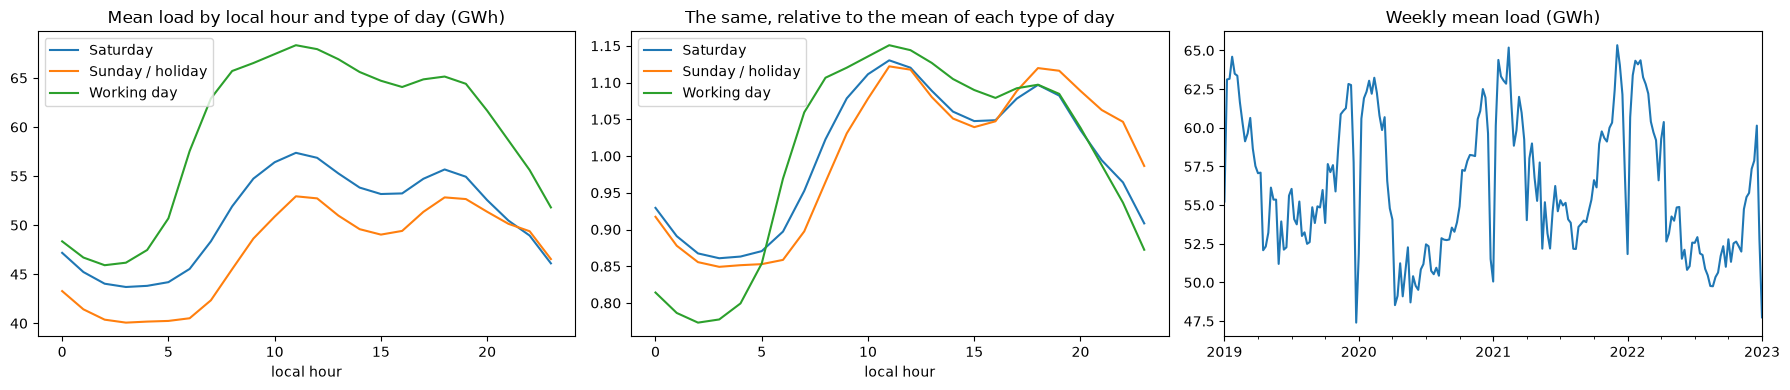

    Saturday  Sunday / holiday  Working day
0      0.929             0.917        0.814
3      0.861             0.849        0.778
6      0.897             0.859        0.969
9      1.078             1.031        1.120
12     1.120             1.118        1.144
15     1.048             1.039        1.090
18     1.097             1.120        1.097
21     0.994             1.063        0.988


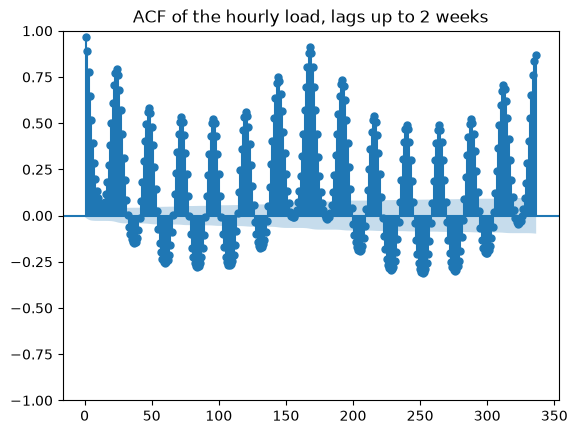

In [4]:
fit_part = data_hourly[data_hourly["date_from"] < "2023-01-01"]

# * type of day: Sunday or public holiday, Saturday (not a holiday), working day
is_sunday_holiday = fit_part["is_holiday"].astype(bool) | (fit_part["day_of_week_raw"] == 6)
day_type = np.select([is_sunday_holiday, fit_part["day_of_week_raw"] == 5], ["Sunday / holiday", "Saturday"], default = "Working day")
profile = fit_part.groupby([fit_part["date_from"].dt.hour.to_numpy(), day_type])["actual_consumption"].mean().unstack()

fig, axes = plt.subplots(1, 3, figsize = (18, 4))
(profile / 1000).plot(ax = axes[0], title = "Mean load by local hour and type of day (GWh)")
axes[0].set_xlabel("local hour")
(profile / profile.mean()).plot(ax = axes[1], title = "The same, relative to the mean of each type of day")
axes[1].set_xlabel("local hour")
(fit_part["actual_consumption"].resample("W").mean() / 1000).plot(ax = axes[2], title = "Weekly mean load (GWh)")
plt.tight_layout()
plt.show()

print((profile / profile.mean()).round(3).iloc[::3])

plot_acf(y[:FIT_END], lags = 24 * 14, zero = False, title = "ACF of the hourly load, lags up to 2 weeks");

**Findings**

- **The daily cycle depends on the type of day.** On working days the load falls to about 46 GWh at night and rises steeply between 05:00 and 08:00 to its maximum of about 68 GWh before noon. On Sundays and holidays it is lower all day (about 40 to 53 GWh) and rises later, between 07:00 and 11:00; Saturdays lie in between. Relative to the mean of each type of day, the load at 06:00 is 0.97 on working days but 0.90 on Saturdays and 0.86 on Sundays and holidays, while at 00:00 it is 0.81 on working days and above 0.9 on the other days. The profiles differ in shape, not only in level, so one daily profile shifted by day-of-week dummies is not enough (see the profiles by type of day in the final X).
- **Yearly cycle and level shifts.** The weekly mean load is highest in winter (about 62 to 65 GWh) and lowest in summer (about 52 GWh), with deep drops at every turn of the year. It also drops in spring 2020 (first COVID lockdown) and stays lower in the autumn and winter of 2022 (energy crisis), as in the daily data.
- **Autocorrelation.** The ACF has peaks at every multiple of 24 hours. They decrease from lag 24 to lags 72 to 120 and rise again towards the weekly lag 168 (about 0.9) and lag 336: the weekly cycle is the strongest dependence after the hour before.

# Features

The candidates are the hourly versions of the daily candidates (e.g. `day_ahead_price` instead of `day_ahead_price_mean`, `shortwave_radiation` instead of `shortwave_radiation_sum`), plus `is_day` and the daily Fourier terms, which only exist in the hourly data. As for the daily data, the correlation and the VIF are computed on 2019–2023.

In [5]:
CUTOFF = "2024-01-01"
data_hourly_train = data_hourly[data_hourly["date_from"] < CUTOFF]       # 2019-2023
h_fit = data_hourly_train.copy()

# * all candidate X (the hourly versions of the daily candidates)
core_h = [
    "is_holiday", "is_weekday", "is_holiday_weekday",
    "weighted_regional_holiday", "weighted_school_holiday",
    "is_bridge_day", "is_christmas_new_year", "is_dst", "is_dst_transition_day",
    "industrial_confidence", "gas_price_eu_usd", "ipi_ei_level", "day_ahead_price",
    "hdd", "shortwave_radiation", "wind_speed_10m", "precipitation", "is_day",
    "solar_capacity_mw", "solar_generation_proxy", "oxcgrt_stringency",
]
time_h = [f"{t}_{p}{k}" for p, K in (("y", 10), ("d", 6)) for k in range(1, K + 1) for t in ("sin", "cos")]

# without time terms
X_global_h = h_fit[core_h].astype(float)

# with the time terms: yearly and daily Fourier terms, month and day-of-week dummies
month_dummies_h = pd.get_dummies(h_fit["month"], prefix = "month", drop_first = True)
dow_dummies_h = pd.get_dummies(h_fit["day_of_week_raw"], prefix = "dow", drop_first = True)
X_global_h_time = pd.concat(
    [
        h_fit[[c for c in core_h if c != "is_weekday"] + time_h],     # is_weekday = sum of the Mon-Fri dummies
        month_dummies_h,
        dow_dummies_h,
    ],
    axis = 1
).astype(float)

## Correlation Analysis
### With Fourier Terms & Time Dummies
#### Linear Correlation

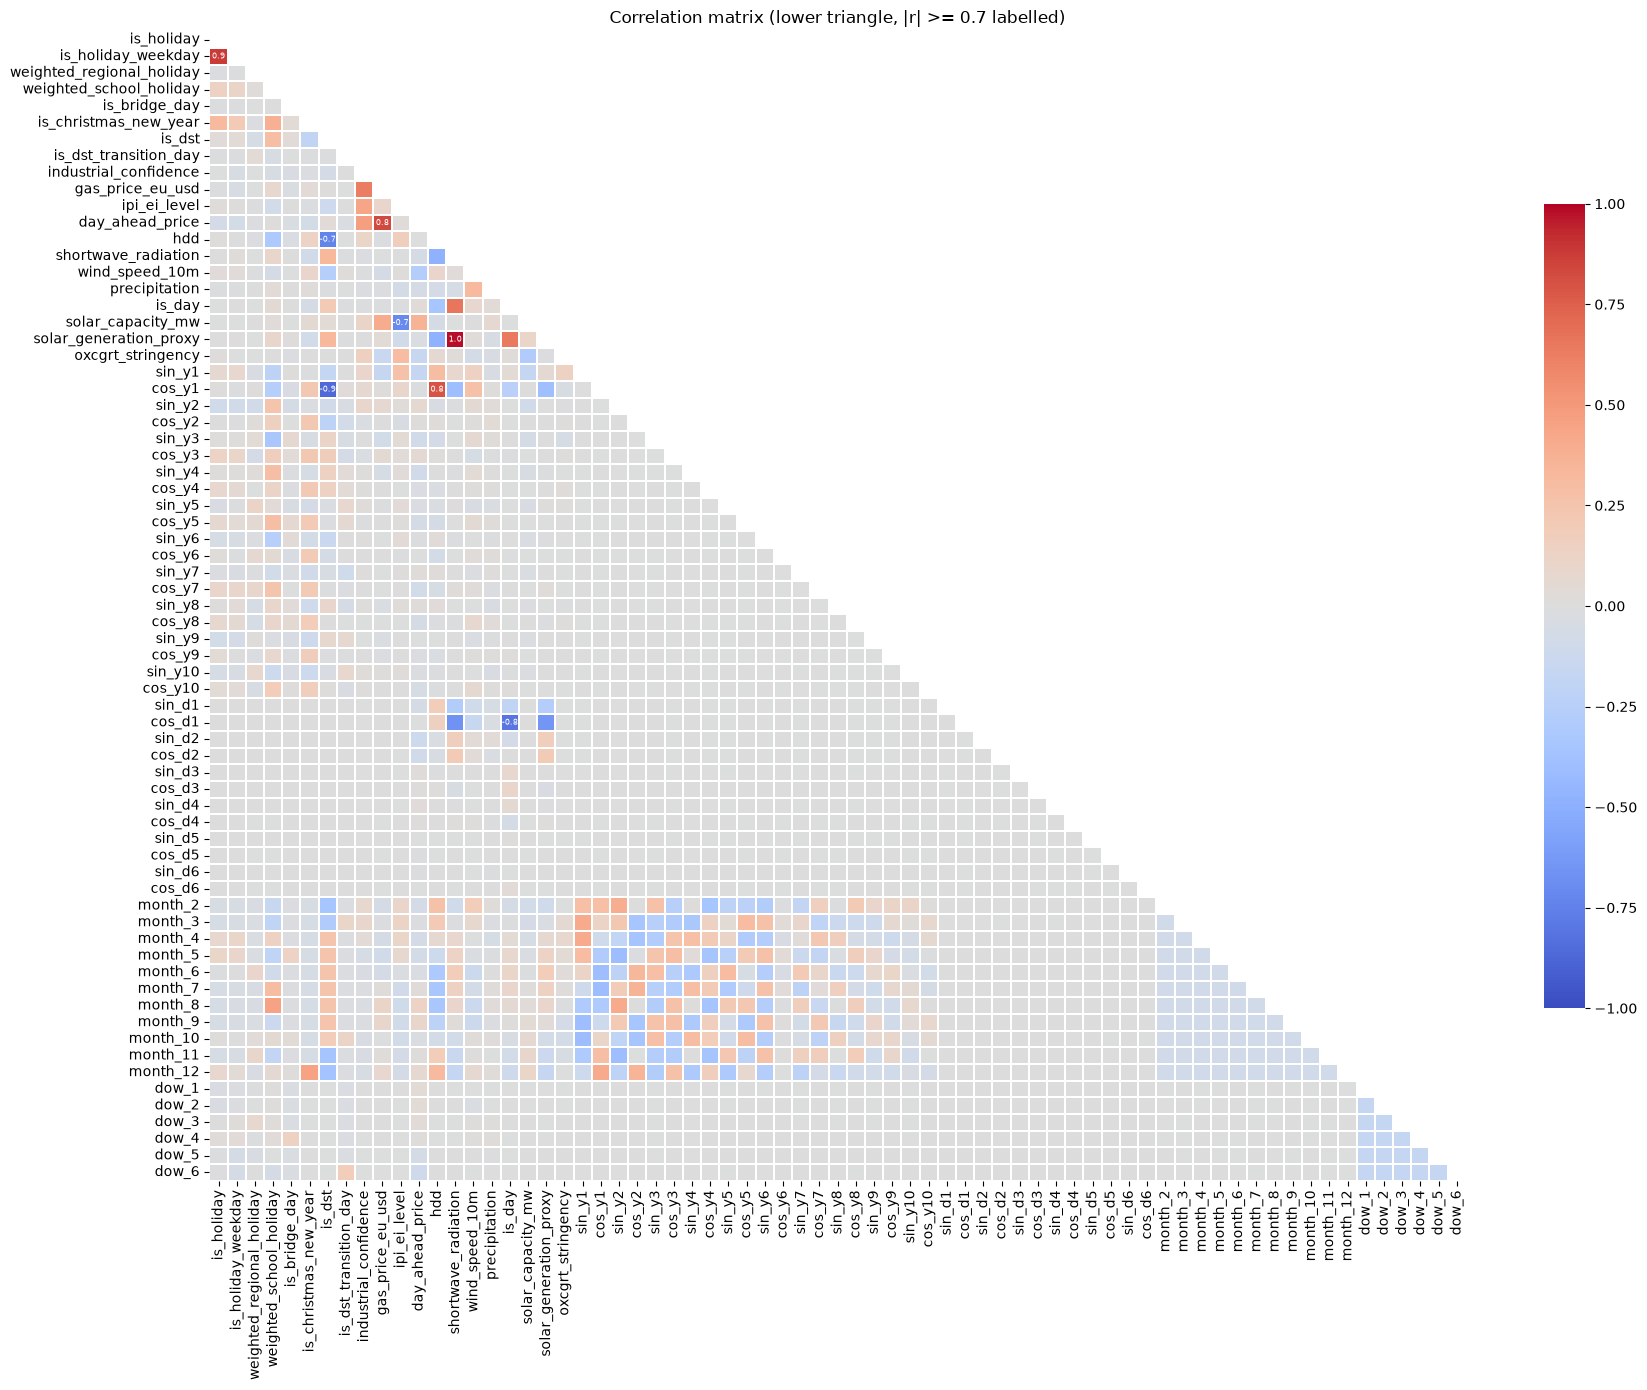

,var_a,var_b,r,abs_r
1255,solar_generation_proxy,shortwave_radiation,0.980711,0.980711
69,is_holiday_weekday,is_holiday,0.879452,0.879452
1455,cos_y1,is_dst,-0.864181,0.864181
768,day_ahead_price,gas_price_eu_usd,0.829714,0.829714
2845,cos_d1,is_day,-0.805446,0.805446
1461,cos_y1,hdd,0.790303,0.790303
834,hdd,is_dst,-0.736990,0.736990
1183,solar_capacity_mw,ipi_ei_level,-0.705097,0.705097


In [6]:
corr = X_global_h_time.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))         
labels = corr.map(lambda v: f"{v:.1f}" if abs(v) >= 0.7 else "")

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, annot=labels, fmt="", annot_kws={"size": 6},
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (lower triangle, |r| >= 0.7 labelled)")
plt.tight_layout()
plt.show()


# print highly correlated feature pairs
pairs = (corr.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_a", "level_1": "var_b"}))
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
pairs[pairs["abs_r"] >= 0.7]

#### VIF Analysis

In [7]:
X_vif_global = (
    add_constant(
        X_global_h_time
        .astype(float)
        .dropna()
    )
)

vif_data = pd.DataFrame({
    "feature": X_vif_global.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_global.values, i)
            for i in range(1, X_vif_global.shape[1])]
})
print(vif_data[vif_data["VIF"] >= 3].sort_values("VIF", ascending = False))

                    feature        VIF
21                   cos_y1  57.502881
20                   sin_y1  51.033581
58                  month_8  43.025161
57                  month_7  42.528257
13      shortwave_radiation  41.393348
59                  month_9  40.636378
56                  month_6  39.636762
18   solar_generation_proxy  38.455258
55                  month_5  37.500173
60                 month_10  37.294915
54                  month_4  32.731529
61                 month_11  31.159563
62                 month_12  26.589944
53                  month_3  25.870260
6                    is_dst  24.453282
22                   sin_y2  21.163094
23                   cos_y2  19.283865
52                  month_2  15.020704
24                   sin_y3  11.281235
25                   cos_y3   9.699392
26                   sin_y4   7.062557
9          gas_price_eu_usd   6.817044
41                   cos_d1   6.099741
30                   sin_y6   6.055506
27                   cos_

### Without Time Terms
#### Linear Correlation

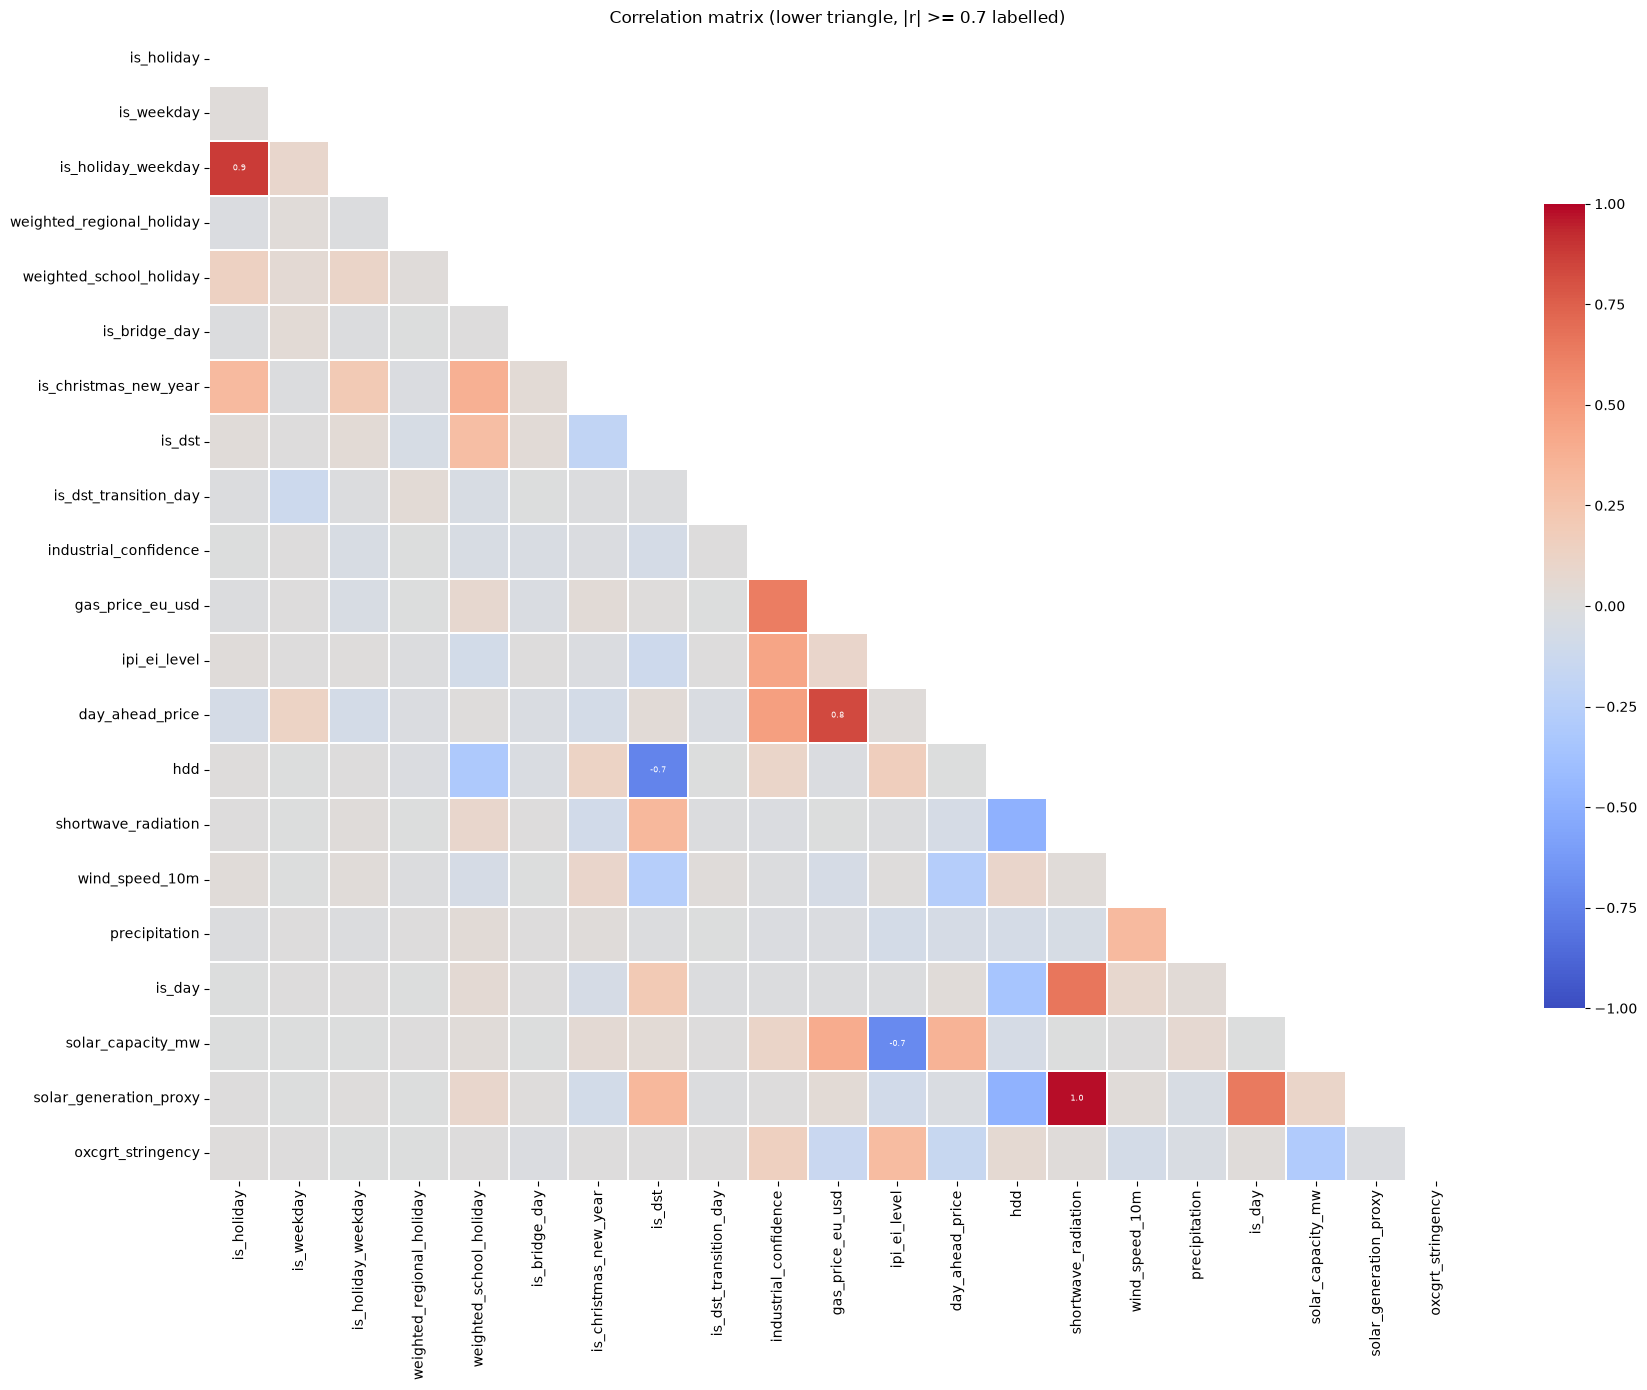

,var_a,var_b,r,abs_r
413,solar_generation_proxy,shortwave_radiation,0.980711,0.980711
42,is_holiday_weekday,is_holiday,0.879452,0.879452
262,day_ahead_price,gas_price_eu_usd,0.829714,0.829714
280,hdd,is_dst,-0.736990,0.736990
389,solar_capacity_mw,ipi_ei_level,-0.705097,0.705097


In [8]:
corr = X_global_h.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))         
labels = corr.map(lambda v: f"{v:.1f}" if abs(v) >= 0.7 else "")

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, annot=labels, fmt="", annot_kws={"size": 6},
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (lower triangle, |r| >= 0.7 labelled)")
plt.tight_layout()
plt.show()


# print highly correlated feature pairs
pairs = (corr.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_a", "level_1": "var_b"}))
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
pairs[pairs["abs_r"] >= 0.7]

#### VIF

In [9]:
X_vif_global = (
    add_constant(
        X_global_h
        .astype(float)
        .dropna()
    )
)

vif_data = pd.DataFrame({
    "feature": X_vif_global.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_global.values, i)
            for i in range(1, X_vif_global.shape[1])]
})
print(vif_data[vif_data["VIF"] >= 3].sort_values("VIF", ascending = False))

                   feature        VIF
14     shortwave_radiation  38.593993
19  solar_generation_proxy  37.972924
10        gas_price_eu_usd   5.857706
0               is_holiday   4.905676
11            ipi_ei_level   4.866723
18       solar_capacity_mw   4.824426
12         day_ahead_price   4.766133
2       is_holiday_weekday   4.673477


#### Findings

The hourly candidates show the same strong correlations as the daily ones (2019–2023):

- `solar_generation_proxy` and `shortwave_radiation`: r = 0.98, VIF about 38 each.
- `is_holiday_weekday` and `is_holiday`: r = 0.88, since most public holidays fall on weekdays. Both are kept (VIF below 5, see Final X): together they separate a holiday on a weekday from one on a weekend.
- `day_ahead_price` and `gas_price_eu_usd`: r = 0.83.
- `cos_y1` and `is_dst`: r = −0.86; `hdd` with `cos_y1` (0.79) and with `is_dst` (−0.74).
- `cos_d1` and `is_day`: r = −0.81.
- `solar_capacity_mw` and `ipi_ei_level`: r = −0.71.
- The month dummies and the first yearly Fourier pairs have VIFs from 15 to 58: they describe the same yearly pattern, so a model uses only one of them.

The X are therefore chosen as for the daily Model 2, whose form is used here:

| Feature | Decision | Reason |
| --- | --- | --- |
| `shortwave_radiation` | excluded | Nearly the same information as `solar_generation_proxy` (r = 0.98), which is kept |
| `solar_capacity_mw` | excluded | Contained in the proxy; on its own a slowly rising trend |
| `gas_price_eu_usd` | excluded | r = 0.83 with `day_ahead_price`; also left out by the daily model and by the tree-based model |
| `is_weekday` | excluded | A linear combination of the day-of-week dummies; replaced by `is_holiday_weekday` |
| `is_dst` | excluded | Collinear with `cos_y1` (r = −0.86), as in the daily Model 2 |
| `is_day` | excluded | A function of the hour and the day of the year (r = −0.81 with `cos_d1`), described by the daily and yearly Fourier terms; the hourly counterpart of `daylight_duration`, which the daily model leaves out |
| month dummies | excluded | The yearly pattern is described by the Fourier terms, as in the daily Model 2 |
| `generation_*` | excluded | Leakage |

## Final X

- **Baseline X** (the hourly columns of the daily X): calendar `is_holiday`, `is_holiday_weekday`, `weighted_regional_holiday`, `weighted_school_holiday`, `is_bridge_day`, `is_christmas_new_year`, `is_dst_transition_day`; economy and price `industrial_confidence`, `ipi_ei_level`, `day_ahead_price`; weather and solar `hdd`, `wind_speed_10m`, `precipitation`, `solar_generation_proxy`; policy `oxcgrt_stringency`.
- **Weekly pattern:** day-of-week dummies `dow_1` to `dow_6` (Monday is the reference).
- **Yearly pattern:** K = 5 yearly Fourier pairs, the number chosen for the daily Model 2. The yearly cycle is the same in daily and hourly data, so K is not chosen again.
- **Daily pattern:** all 6 daily Fourier pairs of the data. The daily profile has steep ramps in the morning and in the evening, so it needs the higher frequencies.
- **Profiles by type of day:** the daily Fourier terms multiplied by `is_saturday` (a Saturday that is not a public holiday) and by `is_sunday_holiday` (a Sunday or a public holiday). Without them every day has the same profile, only shifted by the day-of-week dummies, while the target analysis shows a different shape on Saturdays and on Sundays and holidays.
- A constant (no differencing).

The past-only X (`industrial_confidence`, `ipi_ei_level`, `oxcgrt_stringency`) keep their value of the hour before the origin in all forecasts, as in the shared setup (`frozen_cols`). The day-ahead price is known for the next day, so it is used for all 24 steps.

The continuous X are standardized with the mean and standard deviation of the fit period (2019–2022 for the validation, 2019–2023 for the test); the dummies stay 0 / 1. The VIF below is a check of the baseline X on the fit period.

In [10]:
PAST_ONLY = ["industrial_confidence", "ipi_ei_level", "oxcgrt_stringency"]       # frozen at the hour before the origin
BASE_X = [
    "is_holiday", "is_holiday_weekday", "weighted_regional_holiday", "weighted_school_holiday",
    "is_bridge_day", "is_christmas_new_year", "is_dst_transition_day",
    "industrial_confidence", "ipi_ei_level", "day_ahead_price",
    "hdd", "wind_speed_10m", "precipitation", "solar_generation_proxy",
    "oxcgrt_stringency",
]
K_YEAR, K_DAY = 5, 6
fourier_year = [f"{t}_y{k}" for k in range(1, K_YEAR + 1) for t in ("sin", "cos")]
fourier_day = [f"{t}_d{k}" for k in range(1, K_DAY + 1) for t in ("sin", "cos")]


def build_X(data):
    """ the X of the hourly model, raw (not standardized) """
    is_holiday = data["is_holiday"].astype(bool)
    is_saturday = ((data["day_of_week_raw"] == 5) & ~is_holiday).astype(float)
    is_sunday_holiday = ((data["day_of_week_raw"] == 6) | is_holiday).astype(float)
    # the daily profile on Saturdays and on Sundays / holidays: the daily Fourier terms times the type of day
    profiles = pd.concat(
        {f"{c}_sat": data[c] * is_saturday for c in fourier_day}
        | {f"{c}_sunhol": data[c] * is_sunday_holiday for c in fourier_day},
        axis = 1)
    dow = pd.get_dummies(data["day_of_week_raw"], prefix = "dow", drop_first = True)
    return pd.concat([data[BASE_X + fourier_year + fourier_day], dow, profiles], axis = 1).astype(float)


def standardize(X, fit_end):
    """ standardize the continuous columns with the mean and sd of the data up to fit_end """
    X = X.astype(float).copy()
    cont = [c for c in X.columns if X[c].nunique() > 2]
    mu, sd = X.loc[:fit_end, cont].mean(), X.loc[:fit_end, cont].std()
    X[cont] = (X[cont] - mu) / sd
    return X, mu, sd


X_h_raw = build_X(data_hourly).asfreq("h")                  # 2019-2024
X_h, mu_h, sd_h = standardize(X_h_raw, FIT_END)             # validation: statistics of 2019-2022
X_h = X_h.assign(const = 1.0)                               # no differencing, so a constant
print(X_h.shape, "| missing values:", int(X_h.isna().sum().sum()))

# * VIF of the baseline X (without the Fourier terms, dummies and profiles) on the fit period
X_vif = add_constant(X_h_raw.loc[:FIT_END, BASE_X])
pd.DataFrame(
    {"VIF": [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]}, index = BASE_X
).sort_values("VIF", ascending = False).round(2)

(52608, 68) | missing values: 0


,VIF
is_holiday,4.28
is_holiday_weekday,4.05
industrial_confidence,1.89
day_ahead_price,1.73
hdd,1.70
ipi_ei_level,1.46
is_christmas_new_year,1.44
weighted_school_holiday,1.41
solar_generation_proxy,1.37
wind_speed_10m,1.28


**Findings**

The final X have 68 columns and no missing values from 2019 to 2024. All VIFs of the baseline X are below 5: the highest are `is_holiday` (4.3) and `is_holiday_weekday` (4.1), which are correlated by construction; all other baseline X are below 2. The final X has no problematic collinearity.

# Model: Regression with ARMA Errors in Levels

The daily analysis compared two ways to describe the weekly pattern: a seasonal difference (Model 1) and day-of-week dummies with Fourier terms in levels (Model 2). They were almost equally good (validation RMSE 24,680 vs. 24,710 MWh). For the hourly data only the form of Model 2 is used:

- The weekly cycle is 168 hours. A seasonal difference or a seasonal ARMA term with s = 168 makes the state vector of the model about 170 long, and a fit on four years of hourly data (35,000 hours) becomes too slow.
- The deterministic part (daily and yearly Fourier terms, day-of-week dummies, the profiles by type of day) describes the three cycles; the ARMA errors describe the remaining short-term dependence, with a seasonal term with s = 24 for the dependence on the same hour of the day before.

**Estimation in two steps** (`exog_fit = "ols"`). Unlike the daily models, the coefficients of the X are not estimated together with the ARMA parameters. With about 70 X coefficients and 35,000 hours, a joint maximum likelihood fit with a numerical gradient needs about 8 seconds per iteration (one likelihood takes about 0.1 s, the gradient one likelihood per parameter) and did not finish within an hour. Instead:

1. the X coefficients are estimated by OLS of the load on the X over the fit period;
2. the ARMA parameters and the variance are estimated by maximum likelihood with the X coefficients fixed at these values, so the optimizer has only a few parameters.

OLS is consistent under autocorrelated errors but not efficient, so the X coefficients are somewhat less precise than with a joint fit. They have no standard errors here, and the prediction intervals ignore their uncertainty. AIC and BIC count only the free parameters.

## Stationarity of the Regression Residuals

As for the daily Model 2, a regression in levels is only valid if the regression residuals are stationary (co-integration, FPP3 §10.1). The regression without ARMA terms is fitted by OLS on the fit period: the same estimates as SARIMAX with order (0, 0, 0), but much faster on 35,000 hours. Its residuals are tested with ADF and KPSS, and their ACF and PACF give the candidate ARMA orders.

R² with the type-of-day profiles 0.951, without 0.903 | residual sd 2.17 GWh


/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_10869/862591623.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(resid_ols, maxlag = 48, autolag = "AIC")[1]
/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_10869/862591623.py:12: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(resi

ADF p = 0.0000 (H0: unit root) | KPSS p = 0.010 (H0: stationary)


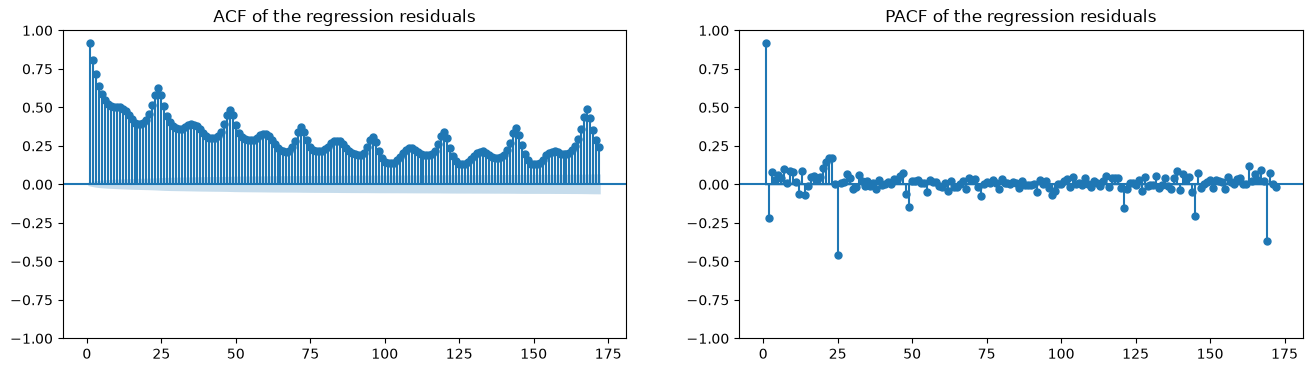

In [11]:
# * regression without ARMA terms on the fit period, by OLS (the same estimates as SARIMAX with order (0, 0, 0))
y_fit, X_fit = y[:FIT_END] / 1000, X_h.loc[:FIT_END]          # GWh
ols = sm.OLS(y_fit, X_fit).fit()
resid_ols = ols.resid

interaction_cols = [c for c in X_h.columns if c.endswith(("_sat", "_sunhol"))]
r2_without = sm.OLS(y_fit, X_fit.drop(columns = interaction_cols)).fit().rsquared
print(f"R² with the type-of-day profiles {ols.rsquared:.3f}, without {r2_without:.3f} | residual sd {resid_ols.std():.2f} GWh")

# * stationarity of the residuals
adf_p = adfuller(resid_ols, maxlag = 48, autolag = "AIC")[1]
kpss_p = kpss(resid_ols, regression = "c", nlags = "auto")[1]
print(f"ADF p = {adf_p:.4f} (H0: unit root) | KPSS p = {kpss_p:.3f} (H0: stationary)")

# * ACF / PACF of the residuals: basis for the candidate orders
fig, (axl, axr) = plt.subplots(1, 2, figsize = (16, 4))
plot_acf(resid_ols, lags = 24 * 7 + 4, zero = False, ax = axl, title = "ACF of the regression residuals");
plot_pacf(resid_ols, lags = 24 * 7 + 4, zero = False, ax = axr, method = "ywm", title = "PACF of the regression residuals");
plt.show()

#### Findings

**Fit of the regression.** The X explain 95.1% of the variance of the hourly load on the fit period (residual standard deviation 2.17 GWh). Without the profiles by type of day it is 90.3%, so the different daily shapes of Saturdays and of Sundays and holidays matter.

**Co-integration.** The two tests disagree: ADF rejects a unit root (p < 0.001), but KPSS rejects stationarity (p ≤ 0.01, the lower end of its table). With 35,000 strongly autocorrelated hours KPSS reacts to slow changes of the level, and the residuals contain such changes (the drops in 2020 and 2022, see the weekly mean load above); the daily data showed the same shifts. The model is kept in levels, as decided for the daily Model 2. The ARMA errors have to describe the slow changes, which the seasonal AR term of the chosen specification does (0.98, close to a unit root, see Order Selection).

**ACF and PACF of the residuals**

- The ACF decays slowly (0.92 at lag 1, 0.55 at lag 6) and peaks again at the daily lags (0.63 at lag 24) and at the weekly lag (0.49 at lag 168).
- The PACF is large at lag 1 (0.92) and negative at lag 2 (−0.22), then small: an AR(2) part.
- Around the daily lag the PACF is positive at lags 21 to 23 (up to 0.17) and clearly negative at lag 25 (−0.46). Such values right next to the seasonal lag appear when the dependence on the hour before and on the same hour of the day before multiply, which points to a seasonal AR term with s = 24 together with the AR(2) part.
- Further negative values at lags 49 and 121 (about −0.15) and at lags 145 and 169 (−0.21 and −0.36) show that one seasonal AR term does not fully describe the dependence on the same hour of earlier days and of the week before. A seasonal MA term with s = 24 lets the seasonal dependence decay over several days. The weekly lag is left to the deterministic terms (day-of-week dummies, profiles by type of day), since a term with s = 168 is too slow (see above).

## Order Selection

The ACF and PACF of the regression residuals give two candidates. Both use the final X and no differencing, and both are estimated in two steps (see above):

| | (p, d, q) | (P, D, Q, s) | Reason |
| --- | --- | --- | --- |
| A | (2, 0, 0) | (1, 0, 0, 24) | PACF at lags 1 and 2 and around the daily lag 24 |
| B | (2, 0, 0) | (1, 0, 1, 24) | The dependence on the same hour of earlier days decays over several days (PACF at lag 49 and later) |

B contains A (with the seasonal MA coefficient at 0), so B is fitted with A's estimates as start values and its likelihood cannot end below that of A. Both use the same OLS coefficients of the X, so they differ only in the ARMA part.

The specification with the **lowest RMSE over all 24 steps** of the validation forecasts (`rmse_all`) is chosen; the 24-hour forecasts are the main hourly horizon of the shared setup. The RMSE of the 1-hour forecasts, AIC and BIC are reported as well. The number of Fourier pairs is fixed (see Final X), not chosen.

In [12]:
# * results of the hourly model: one JSON per experiment
RESULTS_DIR = "results/hourly/model"
TEST_RESULTS_DIR = "results/hourly/test"
results = {}

candidates = {
    "SARIMAX_200100_24": ((2, 0, 0), (1, 0, 0, 24)),      # A
    "SARIMAX_200101_24": ((2, 0, 0), (1, 0, 1, 24)),      # B
}

# start values: the estimates of a specification that the candidate contains (new terms at 0)
start_from = {
    "SARIMAX_200100_24": None,                            # A: default start values
    "SARIMAX_200101_24": "SARIMAX_200100_24",             # B contains A, so A has to be fitted first
}

for name, (order, seasonal_order) in candidates.items():
    start = start_from[name]
    results[name] = fit_eval(
        y, X_h, order, seasonal_order, VAL_START,
        y_scale = 1000, maxiter = 5000,
        start_params = None if start is None else results[start]["res"].params,
        horizon = 24, freq = "h", origins = origins,
        frozen_cols = PAST_ONLY,
        exog_fit = "ols",                                 # two steps: X coefficients by OLS, ARMA by MLE
        lb_lags = (24, 48, 168),
        name = name,
    )
    save_result(name, results[name], RESULTS_DIR)      # save after every fit

summarize(
    results, [*candidates],
    columns = ("aic", "bic", "rmse_all", "rmse_h1", "rmse_h24", "rmse", "first_converged"),
).sort_values("rmse_all")

[SARIMAX_200100_24] refit 1/1 (block from 2022-12-31), 0 left, elapsed 30s, ETA 0s
[SARIMAX_200100_24] forecasts for h = 1..24: 0s
[SARIMAX_200101_24] refit 1/1 (block from 2022-12-31), 0 left, elapsed 39s, ETA 0s
[SARIMAX_200101_24] forecasts for h = 1..24: 0s


,aic,bic,rmse_all,rmse_h1,rmse_h24,rmse,first_converged
SARIMAX_200101_24,70610.64706,70652.971711,1687.600294,1984.19148,1573.047257,675.841726,True
SARIMAX_200100_24,75370.087999,75403.94772,1806.520057,1963.372376,1677.418465,722.213716,True


In [13]:
# * the rule: the lowest RMSE over all 24 steps of the validation forecasts
BEST = min(candidates, key = lambda name: results[name]["rmse_all"])
print("chosen:", BEST)

for name in candidates:
    r = results[name]["res"]
    print(name, f"llf = {r.llf:.1f}, iterations = {r.mle_retvals['iterations']}")
    display(pd.DataFrame({"coef": r.params, "p": r.pvalues}).filter(regex = r"^(ar|ma)\.", axis = 0).round(3))

chosen: SARIMAX_200101_24
SARIMAX_200100_24 llf = -37681.0, iterations = 13


,coef,p
ar.L1,1.034,0.0
ar.L2,-0.139,0.0
ar.S.L24,0.546,0.0


SARIMAX_200101_24 llf = -35300.3, iterations = 22


,coef,p
ar.L1,1.021,0.0
ar.L2,-0.104,0.0
ar.S.L24,0.984,0.0
ma.S.L24,-0.841,0.0


**Result**

| | A: (2,0,0)(1,0,0,24) | **B: (2,0,0)(1,0,1,24)** |
| --- | ---: | ---: |
| RMSE, all 24 steps | 1,807 | **1,688** |
| RMSE, step 1 | 1,963 | 1,984 |
| RMSE, step 24 | 1,677 | 1,573 |
| RMSE, 1-hour forecasts (every hour) | 722 | 676 |
| AIC | 75,370 | 70,611 |

**B is chosen**: its RMSE over all 24 steps is 6.6% lower than that of A. It is also lower at step 24 and for the 1-hour forecasts, and only slightly higher at step 1 (+1%). AIC agrees (−4,760). Both fits converge, in 13 and 22 iterations (about 30 to 40 seconds each with the two-step estimation).

The seasonal terms of B are both significant: AR 0.984 and MA −0.841 (p < 0.001). With a seasonal AR this close to 1, the forecast of the error at an hour mainly follows the error at the same hour of the previous days, weighted with exponentially decreasing weights (the MA term). This lets the model follow slow changes of the level, which the X do not describe. The non-seasonal part is AR 1.021 and −0.104.

## Analysis of Residuals

The residuals of the chosen specification on the fit period (the one-step forecast errors), without the first 4 weeks (start-up of the filter).

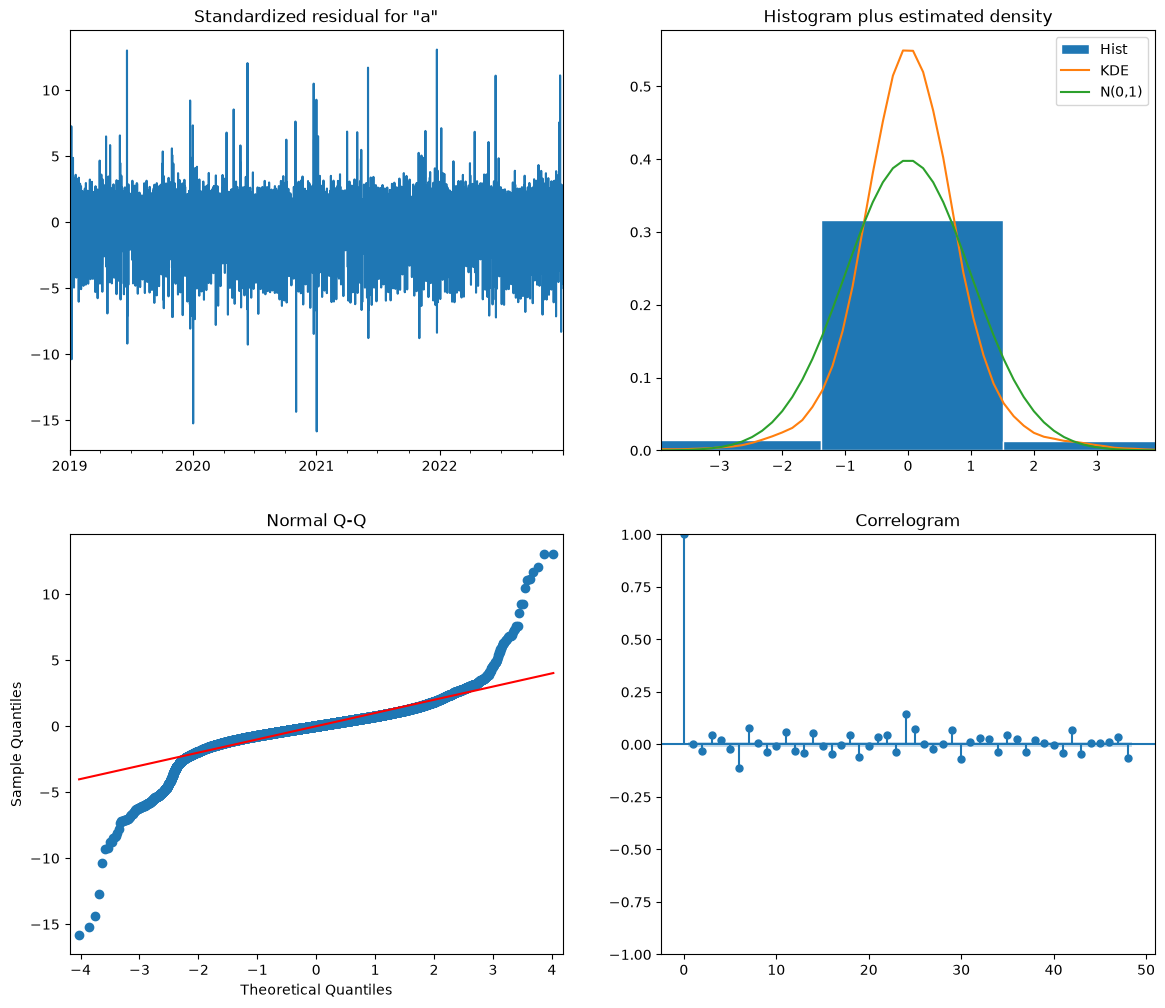

,lb_stat,lb_pvalue
24,2322.988752,0.0
48,3657.325292,0.0
168,16614.739050,0.0


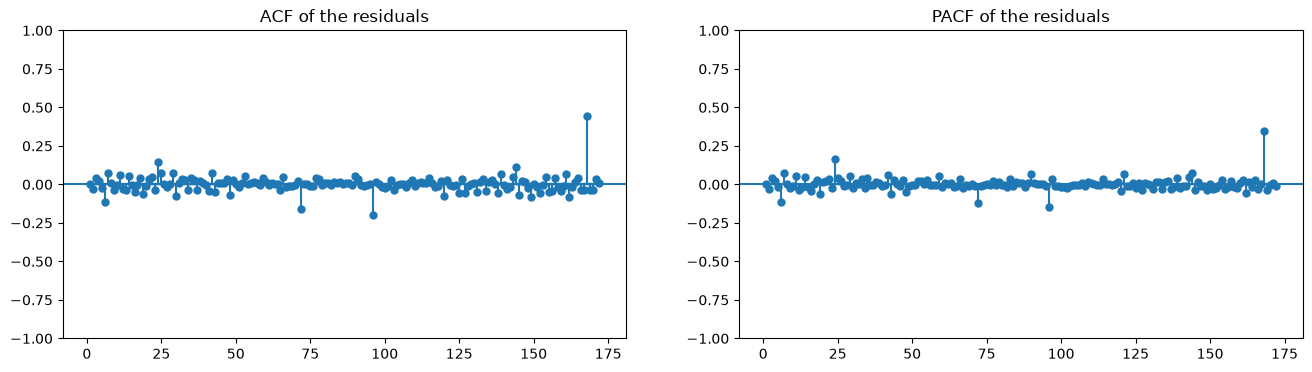

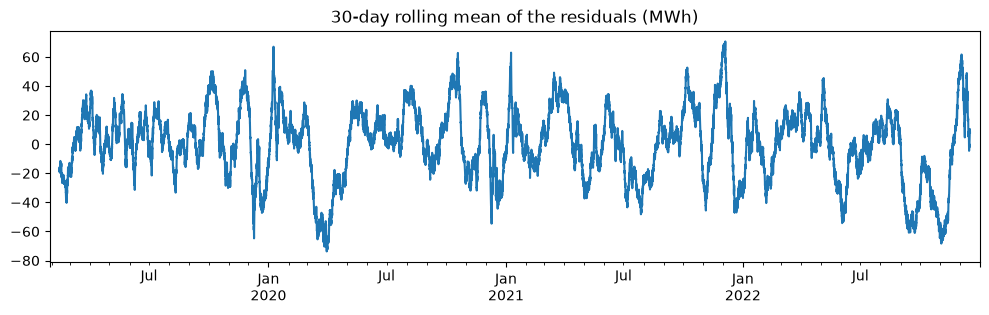

,local time,resid
2021-01-01 23:00:00,2021-01-02,-10488.0
2020-01-01 23:00:00,2020-01-02,-10087.0
2020-11-01 23:00:00,2020-11-02,-9506.0
2021-12-23 23:00:00,2021-12-24,8652.0
2019-06-19 22:00:00,2019-06-20,8607.0
2020-06-10 22:00:00,2020-06-11,7974.0
2021-06-02 22:00:00,2021-06-03,7747.0
2022-12-23 23:00:00,2022-12-24,7359.0
2022-06-15 22:00:00,2022-06-16,7347.0
2020-12-23 23:00:00,2020-12-24,6946.0


In [14]:
res_best = results[BEST]["res"]
resid_best = res_best.resid.iloc[24 * 28:] * 1000          # MWh; the first 4 weeks: start-up of the filter
n_arma = len([p for p in res_best.param_names if p.startswith(("ar.", "ma."))])

res_best.plot_diagnostics(figsize = (14, 12), lags = 48);
plt.show()

# model_df = number of ARMA parameters
display(acorr_ljungbox(resid_best, lags = [24, 48, 168], model_df = n_arma))

fig, (axl, axr) = plt.subplots(1, 2, figsize = (16, 4))
plot_acf(resid_best, lags = 24 * 7 + 4, zero = False, ax = axl, title = "ACF of the residuals");
plot_pacf(resid_best, lags = 24 * 7 + 4, zero = False, ax = axr, method = "ywm", title = "PACF of the residuals");
plt.show()

# the residual mean over time: level shifts (e.g. COVID 2020, energy crisis 2022)
resid_best.rolling(24 * 30, center = True).mean().plot(figsize = (12, 3), title = "30-day rolling mean of the residuals (MWh)");
plt.show()

# the 15 largest residuals, with the local time
largest = resid_best.abs().sort_values(ascending = False).head(15).index
pd.DataFrame({"local time": data_hourly.loc[largest, "date_from"], "resid": resid_best[largest].round(0)})

**Findings**

- **Remaining autocorrelation.** Ljung–Box rejects at lags 24, 48 and 168 (p ≈ 0; with 35,000 hours even small autocorrelations are significant). The largest remaining autocorrelation is at the **weekly lag 168 (about 0.44)**, followed by lag 24 (0.15) and negative values at lags 72 and 96 (about −0.16 and −0.20). The weekly dependence is therefore not fully described by the day-of-week dummies and the profiles by type of day; a seasonal term with s = 168 would be needed, but is too slow (see Model).
- **Normality.** The residuals are strongly heavy-tailed: the standardized residuals reach −15 and +13, and the Q-Q plot leaves the line beyond about ±2.5. This does not bias the point forecasts, but normal intervals are too narrow for extreme quantiles.
- **No lasting level shifts.** The 30-day rolling mean of the residuals stays within about ±70 MWh (about 0.1% of the hourly load). Unlike in the daily Model 2, there are no long periods with a shifted mean in 2020 and 2022: the seasonal AR close to 1 lets the forecasts follow such shifts. The lowest values fall around the turns of the year and in spring 2020.
- **The largest residuals all fall at local midnight, at the start or the end of a holiday**: 2 January (the first working day after New Year), 2 November (after All Saints' Day, a regional holiday), 24 December, 1 January 2021, and Corpus Christi (a regional holiday in June, e.g. 20 and 21 June 2019, 11 and 12 June 2020). A likely cause: the holiday indicators, the regional-holiday share and the day-of-week dummies change the level by the same amount in all 24 hours of a day and switch at midnight, while the actual effect of a holiday is concentrated in the daytime hours. The model therefore moves the level abruptly at midnight, which the night load does not do. The profiles by type of day change the shape only for Saturdays and for Sundays and national holidays (`is_holiday`), not for regional holidays. This also explains why step 1 of the 24-hour forecasts, which is always local midnight, has the largest error (see Validation).

## Conclusion of the Model

The chosen specification is **SARIMAX (2,0,0)(1,0,1,24)** with the final X (baseline X, day-of-week dummies, K = 5 yearly and 6 daily Fourier pairs, profiles by type of day, constant), in levels, estimated in two steps. On the validation year 2023 it reaches an RMSE of 1,688 MWh over all steps of the 24-hour forecasts and 676 MWh for the 1-hour forecasts.

Limitations:

- **Weekly dependence.** The largest remaining autocorrelation is at lag 168; a seasonal term with s = 168 is too slow for four years of hourly data.
- **Holidays and midnight.** The day-level X switch at midnight and act on all hours of a day equally, which causes the largest errors at local midnight around holidays. Interactions of the holiday indicators with the daily Fourier terms (as for Saturdays and Sundays) could reduce them; this was not tried.
- **Heavy tails.** Extreme errors around holidays are much more frequent than under a normal distribution.
- **Two-step estimation.** The X coefficients come from OLS, so they are less precise than in a joint fit and have no standard errors.

# Final Model Evaluation

## Validation: Forecast horizons h = 1 to 24 hours

The validation forecasts were already made during the order selection (`horizon = 24`):

- **24-hour forecasts:** from every local midnight of 2023 whose whole horizon lies inside the year, the next 24 hours, with the actual load up to the hour before the origin and, from the second step on, the model's own forecasts of the load. Reported per step and over all 24 steps together.
- **1-hour forecasts:** every hour of 2023, with the actual load up to the hour before.
- **Information at the origin** (shared setup): the past-only X keep their value of the hour before the origin; the day-ahead price is known for the next day and used for all 24 steps; the weather, calendar and solar X are the actual values of the forecast hours (ex-post).

In [15]:
val = results[BEST]
print(f"{BEST}")
print(f"24-hour forecasts, all steps: RMSE {val['rmse_all']:,.0f} MWh, MAPE {val['mape_all']:.2f}%, bias {val['bias_all']:,.0f} MWh")
print(f"1-hour forecasts, every hour: RMSE {val['rmse']:,.0f} MWh, MAPE {val['mape']:.2f}%")

# * seasonal naive (shared setup): the same hour one week before
naive = evaluate(y[VAL_START:VAL_END], y_all.shift(168)[VAL_START:VAL_END], verbose = False)
print(f"seasonal naive (same hour one week before): RMSE {naive['rmse']:,.0f} MWh, MAPE {naive['mape']:.2f}%")

# one row per step of the 24-hour forecasts
pd.DataFrame({
    h: {m: val[f"{m}_h{h}"] for m in ("rmse", "mape", "bias")} for h in range(1, 25)
}).T.rename_axis("step")

SARIMAX_200101_24
24-hour forecasts, all steps: RMSE 1,688 MWh, MAPE 2.52%, bias -74 MWh
1-hour forecasts, every hour: RMSE 676 MWh, MAPE 0.94%
seasonal naive (same hour one week before): RMSE 3,770 MWh, MAPE 4.64%


,rmse,mape,bias
step,,,
1,1984.191480,3.432084,71.250488
2,1808.089364,3.231962,79.371981
3,1748.117737,3.196632,24.771062
4,1652.937205,2.949476,21.598180
5,1561.880279,2.794814,29.462770
6,1541.964081,2.670123,-45.734862
7,1452.624440,2.173351,-4.753254
8,1762.480465,2.464712,-52.643367
9,1772.952830,2.384189,-40.806810


**Findings**

The 24-hour forecasts are evaluated over the 365 origins of 2023 (every local midnight), the 1-hour forecasts over every hour of 2023.

| | RMSE (MWh) | MAPE | Bias (MWh) |
| --- | ---: | ---: | ---: |
| 24-hour forecasts, all steps | 1,688 | 2.52% | −74 |
| 1-hour forecasts, every hour | 676 | 0.94% | |
| Seasonal naive (same hour one week before) | 3,770 | 4.64% | |

- **Against the seasonal naive forecast** the 24-hour forecasts have a 55% lower RMSE.
- **The error follows the hour of the day more than the horizon.** Every origin is at local midnight, so step k is the local hour k − 1 (except on the two DST days). The RMSE is highest at step 1 (1,984 MWh, local 00:00), falls to 1,453 MWh at step 7 (06:00), rises with the morning ramp (step 8, 1,762 MWh) and in the early afternoon (steps 15 and 16, about 1,860 MWh), and is 1,573 MWh at step 24. The midnight error is the effect described in the residual analysis: at step 1 the 24-hour forecast is the same as the 1-hour forecast, whose RMSE over all hours is only 676 MWh.
- **Bias.** The bias is small at all steps (between −156 and +79 MWh, i.e. below 0.3% of the hourly load).

## Test: Forecasts on 2024

The chosen specification is fitted once on 2019–2023 (the continuous X standardized again with the statistics of 2019–2023) and forecasts 2024 with the same protocol as on the validation year. This is the only run on the test year.

In [16]:
# * X for 2019-2024, standardized with the statistics of the new fit period 2019-2023
X_h_test, mu_test, sd_test = standardize(X_h_raw, VAL_END)
X_h_test = X_h_test.assign(const = 1.0)
print("missing X in 2024:", int(X_h_test.loc[TEST_START:].isna().sum().sum()), "| last hour:", y_all.index.max())

# * fit once on 2019-2023, forecast 2024 for h = 1..24 hours
order_best, seasonal_best = candidates[BEST]
test_result = fit_eval(
    y_all, X_h_test, order_best, seasonal_best, TEST_START,
    y_scale = 1000, maxiter = 5000,
    start_params = results[BEST]["res"].params,     # start values of the ARMA part; the X coefficients come from a new OLS on 2019-2023
    horizon = 24, freq = "h", origins = origins,
    frozen_cols = PAST_ONLY,
    exog_fit = "ols",
    lb_lags = (24, 48, 168),
    name = f"test_{BEST}",
)
save_result(BEST, test_result, TEST_RESULTS_DIR)

print(f"24-hour forecasts, all steps: RMSE {test_result['rmse_all']:,.0f} MWh, MAPE {test_result['mape_all']:.2f}%, bias {test_result['bias_all']:,.0f} MWh")
print(f"1-hour forecasts, every hour: RMSE {test_result['rmse']:,.0f} MWh, MAPE {test_result['mape']:.2f}%")
naive_test = evaluate(y_all[TEST_START:], y_all.shift(168)[TEST_START:], verbose = False)
print(f"seasonal naive (same hour one week before): RMSE {naive_test['rmse']:,.0f} MWh, MAPE {naive_test['mape']:.2f}%")

pd.DataFrame({
    h: {m: test_result[f"{m}_h{h}"] for m in ("rmse", "mape", "bias")} for h in range(1, 25)
}).T.rename_axis("step")

missing X in 2024: 0 | last hour: 2024-12-31 22:00:00
[test_SARIMAX_200101_24] refit 1/1 (block from 2023-12-31), 0 left, elapsed 36s, ETA 0s
[test_SARIMAX_200101_24] forecasts for h = 1..24: 1s
24-hour forecasts, all steps: RMSE 1,798 MWh, MAPE 2.63%, bias 104 MWh
1-hour forecasts, every hour: RMSE 706 MWh, MAPE 0.97%
seasonal naive (same hour one week before): RMSE 4,101 MWh, MAPE 5.14%


,rmse,mape,bias
step,,,
1,2003.574623,3.421263,68.382555
2,1862.473111,3.232443,115.426874
3,1819.132136,3.267610,94.220915
4,1779.402888,3.253636,106.093494
5,1678.917203,3.043566,150.756914
6,1679.725380,2.914277,82.947201
7,1641.782793,2.413857,100.906575
8,1874.992512,2.519402,65.137935
9,1845.200403,2.353668,112.920724


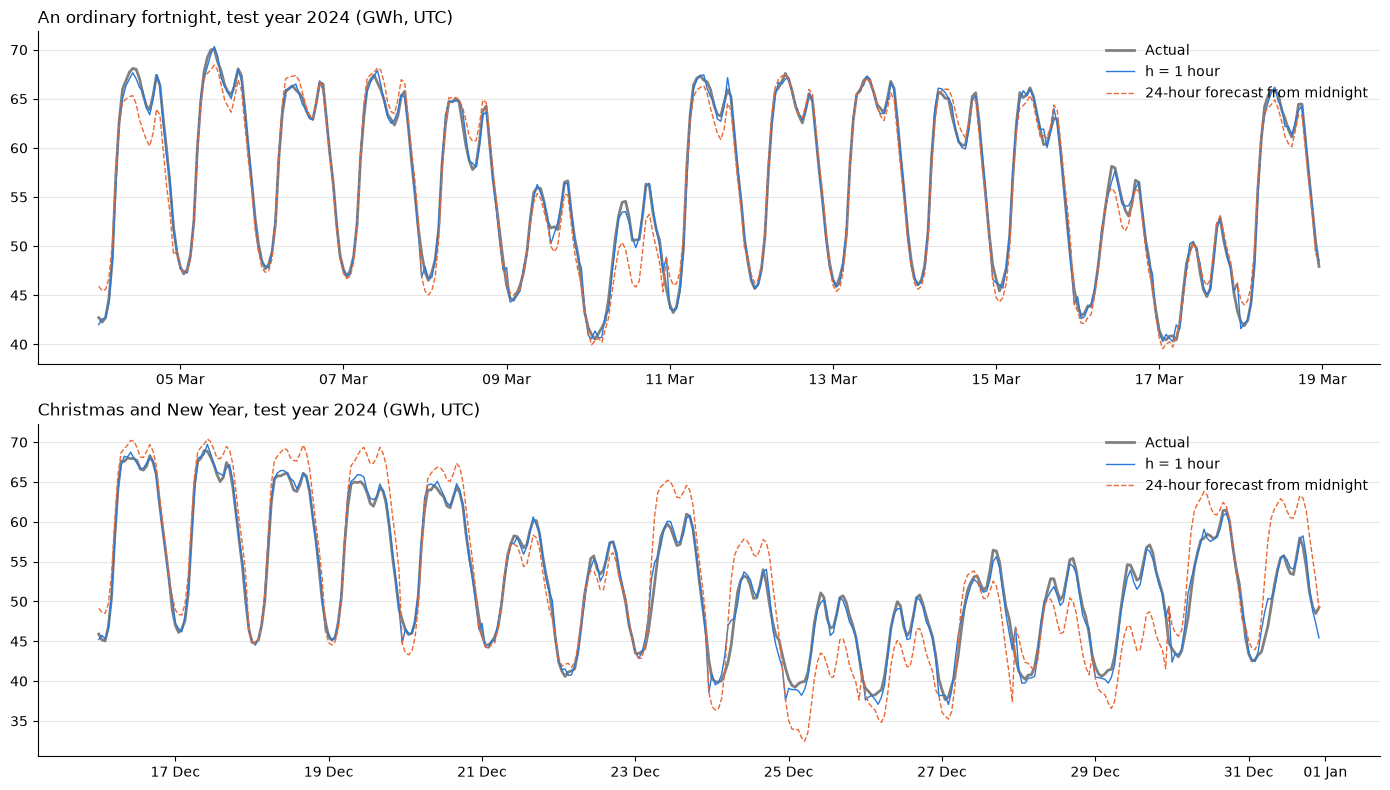

In [17]:
# * the 24-hour forecasts from each local midnight form one path per day: every hour is one step of the path of its day
# (on the DST days the paths overlap by one hour or leave one hour out; the mean takes care of the overlap)
day_ahead = test_result["y_hat_h"].mean(axis = 1) / 1000          # GWh
one_hour = test_result["y_hat"] / 1000
actual = y_all[TEST_START:] / 1000
PERIODS = {"An ordinary fortnight": ("2024-03-04", "2024-03-18"), "Christmas and New Year": ("2024-12-16", "2024-12-31")}

fig, axes = plt.subplots(2, 1, figsize = (14, 8))
for ax, (title, (start, end)) in zip(axes, PERIODS.items()):
    ax.plot(actual[start:end], color = "grey", linewidth = 2, label = "Actual")
    ax.plot(one_hour[start:end], color = "#2a78d6", linewidth = 1, label = "h = 1 hour")
    ax.plot(day_ahead[start:end], color = "#eb6834", linewidth = 1, linestyle = "--", label = "24-hour forecast from midnight")
    ax.set_title(f"{title}, test year 2024 (GWh, UTC)", loc = "left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(axis = "y", alpha = 0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon = False, loc = "upper right")
plt.tight_layout()
plt.show()

**Findings**

The model is fitted once on 2019–2023 (converged) and forecasts 2024; 366 origins.

| | RMSE (MWh) | MAPE | Bias (MWh) |
| --- | ---: | ---: | ---: |
| 24-hour forecasts, all steps | 1,798 | 2.63% | +104 |
| 1-hour forecasts, every hour | 706 | 0.97% | |
| Seasonal naive (same hour one week before) | 4,101 | 5.14% | |

- **Error level.** The errors are slightly higher than on the validation year (+6.5% for the 24-hour forecasts, +4.4% for the 1-hour forecasts); the validation year was used to choose the specification. Against the seasonal naive forecast the 24-hour forecasts have a 56% lower RMSE.
- **By step** the pattern is the same as on the validation year: the highest RMSE at step 1 (local midnight, 2,004 MWh), higher values in the early afternoon (steps 15 and 16, about 1,970 MWh), the lowest at steps 7 and 24 (about 1,640 and 1,624 MWh).
- **Bias.** Slightly positive at all steps (+51 to +165 MWh): the model underestimates the load of 2024 a little, much less than the daily model did.
- **Figure.** In an ordinary fortnight the 1-hour forecasts follow the actual load closely, and the 24-hour forecasts reproduce the daily shape, with errors of a few GWh on single days (e.g. the daytime of Sunday 10 March). Around Christmas the 24-hour forecasts miss the level by several GWh in both directions (too high on 23, 24 and 31 December, too low on 25, 26, 29 and 30 December): these days do not follow the usual pattern of their type of day, and the X describe them only partly.

## Saved model

The test fit is saved as a model (`save_model`): the specification, the estimated parameters, `frozen_cols` and the mean and standard deviation of the raw X on 2019–2023. `load_model` rebuilds it from y and the raw X without a new fit; the same model serves the 1-hour and the 24-hour forecasts.

In [18]:
# * the test fit (2019-2023) as a model: parameters + standardization of the raw X, to forecast without a new fit
MODEL_PATH = Path(TEST_RESULTS_DIR) / "model_24h.json"
save_model(test_result, MODEL_PATH, mu_test, sd_test)

# * check: the loaded model has the same parameters and standardizes the raw X as in the fit
loaded = load_model(MODEL_PATH, y_all, X_h_raw.assign(const = 1.0))
print("params equal", np.allclose(loaded["res"].params, test_result["res"].params),
      "| X equal", np.allclose(loaded["X"].to_numpy(), X_h_test[loaded["x_columns"]].to_numpy()),
      "| converged", loaded["converged"])

params equal True | X equal True | converged True


# Forecast files

The forecasts of the final model are written in the shared format of the project (MODELS.md, Forecast files): one row per origin and step, with the columns `origin` (the UTC time of the first forecast hour), `target_time`, `step`, `y_true`, `y_pred` and the quantiles `q0.1` to `q0.9`. The 1-hour files contain every hour of the year (8,760 in 2023, 8,784 in 2024); the 24-hour files the origins at every local midnight (365 in 2023, 366 in 2024).

The quantiles come from a normal distribution with the forecast standard error. Coverage of the 80% intervals:

| | Validation 2023 | Test 2024 |
| --- | ---: | ---: |
| 1 hour | 87.3% | 84.7% |
| 24 hours | 79.7% | 76.5% |

The 1-hour intervals are too wide: the model has one error variance for all hours, which the large errors at midnight around holidays enlarge, so it is too large for ordinary hours. The 24-hour intervals are about right on the validation year and slightly too narrow on the test year; they ignore the uncertainty of the OLS coefficients and the heavy tails.

In [19]:
def coverage_80(frame):
    """ share of the actual values inside the 80% interval (q0.1 to q0.9), in % """
    return ((frame["y_true"] >= frame["q0.1"]) & (frame["y_true"] <= frame["q0.9"])).mean() * 100

# * forecasts of the final model in the shared format (MODELS.md): validation 2023 and test 2024, horizons 1 h and 24 h
for H in (1, 24):
    frame_val = forecast_frame(results[BEST], y, H)
    frame_test = forecast_frame(test_result, y_all, H)
    frame_val.to_csv(Path(RESULTS_DIR) / f"sarimax_hourly_{H}h_val.csv", index = False)
    frame_test.to_csv(Path(TEST_RESULTS_DIR) / f"sarimax_hourly_{H}h_test.csv", index = False)
    print(f"{H}h: validation {frame_val['origin'].nunique()} origins, 80% coverage {coverage_80(frame_val):.1f}% | "
          f"test {frame_test['origin'].nunique()} origins, 80% coverage {coverage_80(frame_test):.1f}%")

forecast_frame(test_result, y_all, 24).head(26)

1h: validation 8760 origins, 80% coverage 87.3% | test 8784 origins, 80% coverage 84.7%
24h: validation 365 origins, 80% coverage 79.7% | test 366 origins, 80% coverage 76.5%


,origin,target_time,step,y_true,y_pred,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
0,2023-12-31 23:00:00,2023-12-31 23:00:00,1,40170.25,40051.862987,39212.523745,39500.651669,39708.412173,39885.935863,40051.862987,40217.790111,40395.313802,40603.074306,40891.202230
1,2023-12-31 23:00:00,2024-01-01 00:00:00,2,38818.25,37266.570360,36067.455640,36479.087096,36775.902337,37029.520015,37266.570360,37503.620705,37757.238384,38054.053624,38465.685080
2,2023-12-31 23:00:00,2024-01-01 01:00:00,3,37847.75,36034.486758,34600.459402,35092.731541,35447.694388,35750.997052,36034.486758,36317.976463,36621.279128,36976.241974,37468.514113
3,2023-12-31 23:00:00,2024-01-01 02:00:00,4,37123.25,36052.546175,34450.868031,35000.691243,35397.152462,35735.913955,36052.546175,36369.178396,36707.939889,37104.401108,37654.224319
4,2023-12-31 23:00:00,2024-01-01 03:00:00,5,36753.75,35917.922848,34190.839906,34783.712009,35211.214508,35576.499630,35917.922848,36259.346067,36624.631189,37052.133687,37645.005790
5,2023-12-31 23:00:00,2024-01-01 04:00:00,6,37051.25,35094.504519,33271.025403,33896.988333,34348.351645,34734.024953,35094.504519,35454.984084,35840.657392,36292.020704,36917.983634
6,2023-12-31 23:00:00,2024-01-01 05:00:00,7,36725.50,34700.681197,32801.818115,33453.658812,33923.681815,34325.299141,34700.681197,35076.063253,35477.680579,35947.703582,36599.544280
7,2023-12-31 23:00:00,2024-01-01 06:00:00,8,37321.00,35806.539130,33848.035721,34520.349718,35005.135410,35419.366909,35806.539130,36193.711350,36607.942849,37092.728542,37765.042538
8,2023-12-31 23:00:00,2024-01-01 07:00:00,9,37984.25,38675.551888,36669.474561,37358.119707,37854.681307,38278.974885,38675.551888,39072.128891,39496.422469,39992.984069,40681.629214
9,2023-12-31 23:00:00,2024-01-01 08:00:00,10,39952.00,41967.299306,39923.044193,40624.794989,41130.806684,41563.175021,41967.299306,42371.423592,42803.791929,43309.803624,44011.554420


# Conclusion

- **Final model.** SARIMAX (2,0,0)(1,0,1,24) in levels with the baseline X, day-of-week dummies, K = 5 yearly and 6 daily Fourier pairs and the daily profiles of Saturdays and of Sundays and holidays. The X coefficients are estimated by OLS and the ARMA parameters by maximum likelihood (two steps), since a joint fit of about 70 coefficients on 35,000 hours did not finish within an hour. It was chosen over (2,0,0)(1,0,0,24) by the RMSE over all steps of the 24-hour forecasts on 2023 (1,688 vs. 1,807 MWh).
- **Test year 2024.** Fitted once on 2019–2023, the model reaches an RMSE of 706 MWh (MAPE 0.97%) for the 1-hour forecasts and 1,798 MWh (MAPE 2.63%) over the 24-hour forecasts, 56% below the seasonal naive forecast. The bias is small (+104 MWh).
- **Information at the origin.** As in the shared setup, the past-only X keep their value of the hour before the origin and the day-ahead price is used for the next 24 hours; the weather is observed (ex-post), which is optimistic compared with a deployment that would use weather forecasts.
- **Limitations.** The largest errors fall at local midnight around holidays, since the day-level X act on all hours of a day equally and switch at midnight; the weekly dependence (lag 168) is not fully described; the residuals are heavy-tailed; the 1-hour intervals are too wide and the 24-hour intervals slightly too narrow on 2024.